# Airline Operations & Performance Analysis – Data Analyst Project
**Dataset:** Airline flight operations | **Tools:** Python, pandas, matplotlib, seaborn

## 1. Business problem
An airline operations team wants to understand flight operations, passenger demand, ticket pricing and arrival delays so it can identify patterns and areas for operational improvement.

**Questions we will answer**
1. What does the overall flight and delay performance look like?
2. How are distance, passengers, turnaround time and ticket price distributed?
3. Do delays differ by origin city, aircraft type, departure slot or weather?
4. Which flights have significant arrival delays?
5. What operational insights and recommendations can be drawn from the data?

**Note:** This is an exploratory analysis of the supplied dataset. Associations do not establish causation.

In [2]:
%pip install matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## 2. Import libraries

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi']=100

## 3. Load and inspect the data

In [16]:
df = pd.read_csv('../data/raw/airlines_data.csv')
print('Rows, Columns:', df.shape)
df.head()

Rows, Columns: (255, 11)


,Flight_ID,Origin_City,Aircraft_Type,Departure_Slot,Weather,Distance_Km,Passengers,Turnaround_Time_Min,Ticket_Price_INR,Flight_Date,Arrival_Delay_Min
0,F1035,Hyderabad,Narrow_Body,Night,Rain,1470,135.0,78.0,4200,2025-10-27,23.0
1,F1053,Bengaluru,Narrow_Body,Evening,Clear,1270,140.0,61.0,5000,2026-09-06,18.0
2,F1223,Delhi,Wide_Body,Night,Clear,1560,279.0,77.0,4150,2025-04-15,42.0
3,F1234,Delhi,Narrow_Body,Night,Clear,1380,181.0,66.0,9600,2025-01-20,25.0
4,F1209,Hyderabad,Narrow_Body,Morning,Rain,1750,160.0,72.0,5000,2025-01-17,29.0


In [17]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 255 entries, 0 to 254
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Flight_ID            255 non-null    str    
 1   Origin_City          255 non-null    str    
 2   Aircraft_Type        255 non-null    str    
 3   Departure_Slot       255 non-null    str    
 4   Weather              250 non-null    str    
 5   Distance_Km          255 non-null    int64  
 6   Passengers           250 non-null    float64
 7   Turnaround_Time_Min  250 non-null    float64
 8   Ticket_Price_INR     255 non-null    int64  
 9   Flight_Date          255 non-null    str    
 10  Arrival_Delay_Min    250 non-null    float64
dtypes: float64(3), int64(2), str(6)
memory usage: 22.0 KB


In [18]:
print('Missing values per column:'); print(df.isna().sum()[df.isna().sum()>0])
print('\nDuplicate rows:', df.duplicated().sum())
df.describe(include='all').round(1)

Missing values per column:
Weather                5
Passengers             5
Turnaround_Time_Min    5
Arrival_Delay_Min      5
dtype: int64

Duplicate rows: 5


,Flight_ID,Origin_City,Aircraft_Type,Departure_Slot,Weather,Distance_Km,Passengers,Turnaround_Time_Min,Ticket_Price_INR,Flight_Date,Arrival_Delay_Min
count,255,255,255,255,250,255.0,250.0,250.0,255.0,255,250.0
unique,250,11,3,4,3,NaN,NaN,NaN,NaN,208,NaN
top,F1053,Mumbai,Narrow_Body,Morning,Clear,NaN,NaN,NaN,NaN,2026-04-18,NaN
freq,2,79,151,86,163,NaN,NaN,NaN,NaN,3,NaN
mean,NaN,NaN,NaN,NaN,NaN,1278.3,152.3,69.7,6579.6,NaN,24.9
std,NaN,NaN,NaN,NaN,NaN,555.6,63.0,17.2,2124.1,NaN,15.7
min,NaN,NaN,NaN,NaN,NaN,-1200.0,38.0,30.0,2200.0,NaN,-10.0
25%,NaN,NaN,NaN,NaN,NaN,930.0,94.8,58.0,5100.0,NaN,14.0
50%,NaN,NaN,NaN,NaN,NaN,1280.0,154.5,70.0,6550.0,NaN,25.0
75%,NaN,NaN,NaN,NaN,NaN,1640.0,175.8,79.8,7950.0,NaN,35.8


**Initial data checks:** The dataset contains flight identifiers, route origin, aircraft and departure categories, weather, operational measures, ticket prices, flight dates and arrival delays. Missing values and duplicate rows are checked before analysis. The notebook does not assume that any particular delay or operational value is invalid without a stated business rule.

## 4. Clean the data

In [19]:
clean = df.copy()
# 1. Remove duplicate rows
clean = clean.drop_duplicates()
# 2. Standardise text fields
text_cols = ['Origin_City','Aircraft_Type','Departure_Slot','Weather']
for c in text_cols:
    clean[c] = clean[c].astype('string').str.strip().str.replace(r'\\s+', ' ', regex=True).str.title()
# 3. Convert date values
clean['Flight_Date'] = pd.to_datetime(clean['Flight_Date'], errors='coerce')
# 4. Convert numeric fields and fill missing numeric values with the median
num_cols = ['Distance_Km','Passengers','Turnaround_Time_Min','Ticket_Price_INR','Arrival_Delay_Min']
for c in num_cols:
    clean[c] = pd.to_numeric(clean[c], errors='coerce')
    clean[c] = clean[c].fillna(clean[c].median())
# 5. Fill missing categorical values with the mode (or 'Unknown' if no mode exists)
for c in text_cols:
    mode = clean[c].mode(dropna=True)
    clean[c] = clean[c].fillna(mode.iloc[0] if not mode.empty else 'Unknown')
print('Rows after cleaning:', len(clean), '| Missing values left:', clean.isna().sum().sum())

Rows after cleaning: 250 | Missing values left: 0


## 5. Create new columns (feature engineering)

In [20]:
# Revenue proxy based on recorded passengers and average ticket price
clean['Estimated_Revenue_INR'] = clean['Passengers'] * clean['Ticket_Price_INR']
# Delay groups are descriptive categories; 15 minutes is used as an analysis threshold
clean['Delay_Band'] = pd.cut(
    clean['Arrival_Delay_Min'],
    bins=[-np.inf, 0, 15, 60, np.inf],
    labels=['On Time / Early','1-15 Min','16-60 Min','Over 60 Min']
)
clean['Flight_Month'] = clean['Flight_Date'].dt.strftime('%Y-%m')
clean['Day_of_Week'] = clean['Flight_Date'].dt.day_name()
clean[['Flight_ID','Arrival_Delay_Min','Delay_Band','Estimated_Revenue_INR','Flight_Month']].head()

,Flight_ID,Arrival_Delay_Min,Delay_Band,Estimated_Revenue_INR,Flight_Month
0,F1035,23.0,16-60 Min,567000.0,2025-10
1,F1053,18.0,16-60 Min,700000.0,2026-09
2,F1223,42.0,16-60 Min,1157850.0,2025-04
3,F1234,25.0,16-60 Min,1737600.0,2025-01
4,F1209,29.0,16-60 Min,800000.0,2025-01


## 6. Exploratory data analysis (EDA)

### Q1. Overall flight and delay performance

       Arrival_Delay_Min  Distance_Km  Passengers  Turnaround_Time_Min  \
count              250.0        250.0       250.0                250.0   
mean                25.1       1283.7       153.1                 69.7   
std                 15.7        558.2        62.5                 17.0   
min                -10.0      -1200.0        38.0                 30.0   
25%                 14.2        932.5       116.5                 58.0   
50%                 25.0       1290.0       155.0                 70.0   
75%                 35.8       1640.0       175.8                 79.0   
max                 69.0       2800.0       320.0                126.0   

       Ticket_Price_INR  
count             250.0  
mean             6597.0  
std              2120.5  
min              2200.0  
25%              5150.0  
50%              6600.0  
75%              7950.0  
max             12150.0  


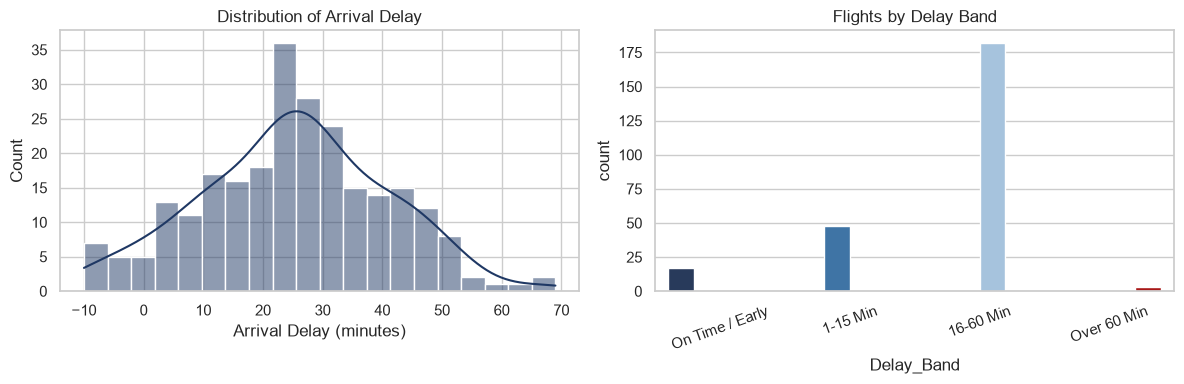

In [21]:
print(clean[['Arrival_Delay_Min','Distance_Km','Passengers','Turnaround_Time_Min','Ticket_Price_INR']].describe().round(1))
fig,ax=plt.subplots(1,2,figsize=(12,4))
sns.histplot(clean['Arrival_Delay_Min'],bins=20,kde=True,color='#1F3864',ax=ax[0])
ax[0].set_title('Distribution of Arrival Delay'); ax[0].set_xlabel('Arrival Delay (minutes)')
delay_order=['On Time / Early','1-15 Min','16-60 Min','Over 60 Min']
sns.countplot(data=clean,x='Delay_Band',hue='Delay_Band',legend=False,order=delay_order,
              palette=['#1F3864','#2E75B6','#9DC3E6','#C00000'],ax=ax[1])
ax[1].set_title('Flights by Delay Band'); ax[1].tick_params(axis='x',rotation=20)
plt.tight_layout();plt.savefig('../images/01_overall_performance.png');plt.show()

### Q2. Do operational factors relate to arrival delays?

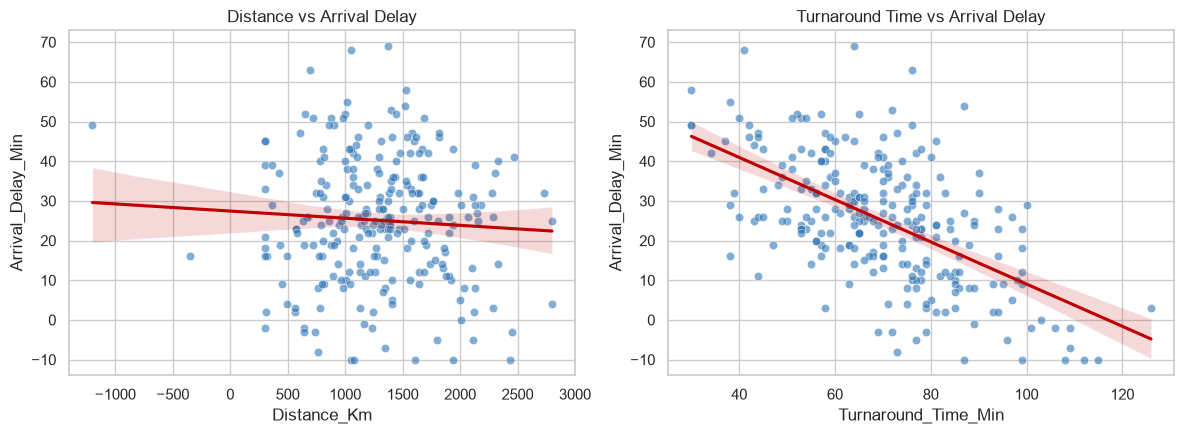

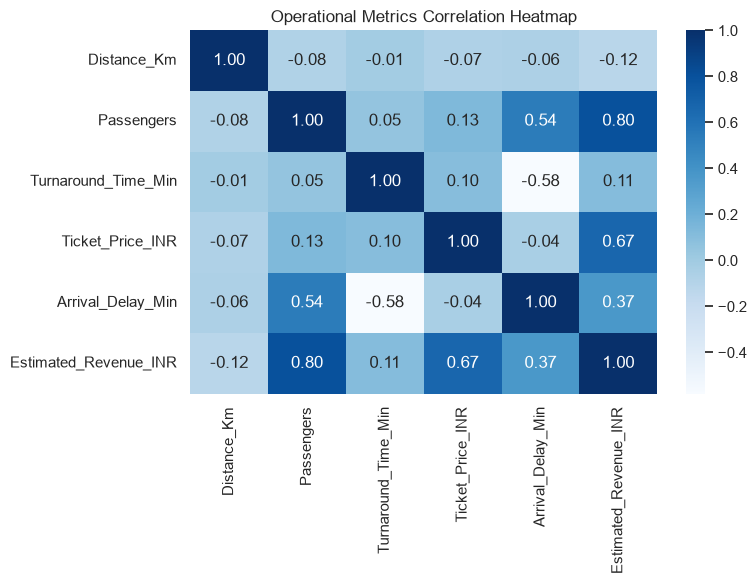

In [10]:
fig,ax=plt.subplots(1,2,figsize=(12,4.5))
sns.scatterplot(data=clean,x='Distance_Km',y='Arrival_Delay_Min',alpha=.6,color='#2E75B6',ax=ax[0])
sns.regplot(data=clean,x='Distance_Km',y='Arrival_Delay_Min',scatter=False,color='#C00000',ax=ax[0])
ax[0].set_title('Distance vs Arrival Delay')
sns.scatterplot(data=clean,x='Turnaround_Time_Min',y='Arrival_Delay_Min',alpha=.6,color='#2E75B6',ax=ax[1])
sns.regplot(data=clean,x='Turnaround_Time_Min',y='Arrival_Delay_Min',scatter=False,color='#C00000',ax=ax[1])
ax[1].set_title('Turnaround Time vs Arrival Delay')
plt.tight_layout();plt.savefig('../images/02_operational_factors.png');plt.show()

corr_cols=['Distance_Km','Passengers','Turnaround_Time_Min','Ticket_Price_INR','Arrival_Delay_Min','Estimated_Revenue_INR']
plt.figure(figsize=(8,6))
sns.heatmap(clean[corr_cols].corr().round(2),annot=True,cmap='Blues',fmt='.2f')
plt.title('Operational Metrics Correlation Heatmap')
plt.tight_layout();plt.savefig('../images/03_correlation.png');plt.show()

### Q3. Does performance differ by origin, aircraft, departure slot or weather?

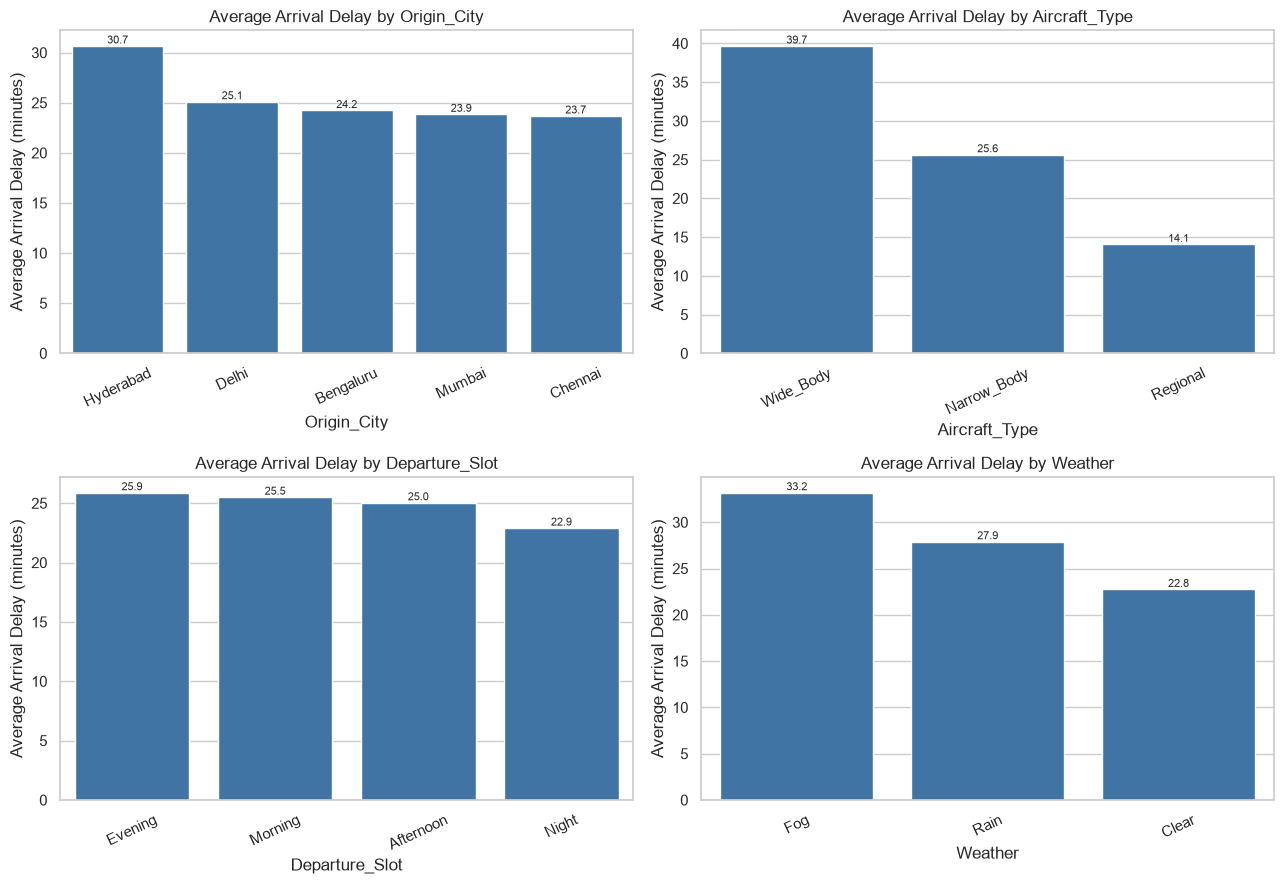

In [22]:
fig,ax=plt.subplots(2,2,figsize=(13,9))
for a,col in zip(ax.flat,['Origin_City','Aircraft_Type','Departure_Slot','Weather']):
    order=clean.groupby(col)['Arrival_Delay_Min'].mean().sort_values(ascending=False).index
    sns.barplot(data=clean,x=col,y='Arrival_Delay_Min',order=order,errorbar=None,color='#2E75B6',ax=a)
    a.set_title(f'Average Arrival Delay by {col}')
    a.set_ylabel('Average Arrival Delay (minutes)')
    a.tick_params(axis='x',rotation=25)
    for p in a.patches:
        if not np.isnan(p.get_height()):
            a.annotate(f'{p.get_height():.1f}',(p.get_x()+p.get_width()/2,p.get_height()),
                       ha='center',va='bottom',fontsize=8)
plt.tight_layout();plt.savefig('../images/04_group_comparison.png');plt.show()

### Q4. Which flights have significant arrival delays?

In [23]:
risk = clean[clean['Arrival_Delay_Min']>15].sort_values('Arrival_Delay_Min',ascending=False)
print(f'{len(risk)} flights ({len(risk)/len(clean):.1%}) have arrival delays above 15 minutes.')
print('Average delay for these flights:', round(risk['Arrival_Delay_Min'].mean(),1), 'minutes')
print('Overall average arrival delay:', round(clean['Arrival_Delay_Min'].mean(),1), 'minutes')
risk[['Flight_ID','Origin_City','Aircraft_Type','Departure_Slot','Weather','Arrival_Delay_Min']].head(10)

185 flights (74.0%) have arrival delays above 15 minutes.
Average delay for these flights: 32.1 minutes
Overall average arrival delay: 25.1 minutes


,Flight_ID,Origin_City,Aircraft_Type,Departure_Slot,Weather,Arrival_Delay_Min
183,F1233,Bengaluru,Wide_Body,Afternoon,Fog,69.0
109,F1049,Delhi,Wide_Body,Afternoon,Clear,68.0
140,F1231,Delhi,Wide_Body,Evening,Fog,63.0
203,F1057,Delhi,Wide_Body,Evening,Clear,58.0
224,F1019,Delhi,Wide_Body,Afternoon,Clear,55.0
128,F1182,Bengaluru,Wide_Body,Afternoon,Rain,54.0
132,F1128,Chennai,Wide_Body,Evening,Fog,53.0
192,F1240,Delhi,Wide_Body,Evening,Rain,52.0
182,F1185,Hyderabad,Wide_Body,Evening,Clear,52.0
252,F1091,Hyderabad,Wide_Body,Afternoon,Rain,52.0


## 7. Key insights (generated from the data)

In [24]:
r_dist=clean['Distance_Km'].corr(clean['Arrival_Delay_Min'])
r_turn=clean['Turnaround_Time_Min'].corr(clean['Arrival_Delay_Min'])
city_avg=clean.groupby('Origin_City')['Arrival_Delay_Min'].mean()
aircraft_avg=clean.groupby('Aircraft_Type')['Arrival_Delay_Min'].mean()
weather_avg=clean.groupby('Weather')['Arrival_Delay_Min'].mean()
print(f"1. Average arrival delay: {clean['Arrival_Delay_Min'].mean():.1f} minutes; median: {clean['Arrival_Delay_Min'].median():.1f} minutes.")
print(f"2. Distance vs arrival delay correlation = {r_dist:.2f}; turnaround time vs arrival delay = {r_turn:.2f}.")
print(f"3. Highest average delay by origin city: {city_avg.idxmax()} ({city_avg.max():.1f} minutes).")
print(f"4. Highest average delay by aircraft type: {aircraft_avg.idxmax()} ({aircraft_avg.max():.1f} minutes).")
print(f"5. Highest average delay by weather category: {weather_avg.idxmax()} ({weather_avg.max():.1f} minutes).")
print(f"6. {len(risk)} flights ({len(risk)/len(clean):.1%}) have delays above 15 minutes.")

1. Average arrival delay: 25.1 minutes; median: 25.0 minutes.
2. Distance vs arrival delay correlation = -0.06; turnaround time vs arrival delay = -0.58.
3. Highest average delay by origin city: Hyderabad (30.7 minutes).
4. Highest average delay by aircraft type: Wide_Body (39.7 minutes).
5. Highest average delay by weather category: Fog (33.2 minutes).
6. 185 flights (74.0%) have delays above 15 minutes.


## 8. Recommendations
- Review flight operations at origin cities and categories that show higher average arrival delays.
- Examine turnaround processes to identify operational bottlenecks; the correlation analysis alone cannot establish cause.
- Monitor weather-related delay patterns and use the findings to support operational planning.
- Track flights delayed by more than 15 minutes and investigate recurring patterns by date, departure slot and aircraft type.
- Use passenger counts and ticket prices to estimate revenue patterns, while treating the calculated revenue as a simple proxy rather than audited financial revenue.

> **Remember:** correlation does not prove causation. This analysis shows patterns and associations in the supplied dataset.

## 9. Save the cleaned data

In [25]:
clean.to_csv('../data/processed/airlines_data_clean.csv',index=False)
print('Saved cleaned file with', len(clean), 'rows')

Saved cleaned file with 250 rows
